# 1. Forest Fires Regression Project
### Predicting the Burned Area of Forest Fires in Northeast Portugal


## 2. Project Description

This project uses the **Forest Fires** dataset from the UCI Machine Learning Repository.
The dataset contains 517 instances and 12 input features describing meteorological,
temporal, and spatial conditions in the Montesinho natural park region of northeast
Portugal. The target variable, `area`, represents the burned area of the forest in
hectares and ranges from 0.00 to 1090.84 in the supplied data.

A key characteristic of the target is that it is **highly skewed toward zero** — a large
share of recorded fires burned effectively no measurable area. The dataset documentation
suggests that a logarithmic transformation of the target may be appropriate; this project
investigates that question empirically rather than assuming it.


## 3. Problem Statement

**Scenario:** I have been engaged as a data scientist to investigate whether
meteorological conditions, temporal information, and spatial coordinates can be used to
estimate the burned area associated with forest fires.

**Primary objective:** Build and evaluate machine-learning regression models capable of
predicting the burned area of a forest fire (`area`, in hectares), using a complete
data-science workflow — from data understanding and exploratory analysis through
preprocessing, feature engineering, regression modeling, evaluation, and interpretation.


## 4. Project Objectives

- Understand the structure and meaning of the Forest Fires dataset.
- Inspect the data for quality issues before modeling.
- Perform comprehensive exploratory data analysis (EDA).
- Investigate relationships between environmental variables and burned area.
- Engineer useful features from the temporal variables.
- Prepare categorical and numerical variables appropriately for machine learning.
- Investigate the highly skewed target variable, including a `log1p` transformation.
- Train at least two regression models.
- Evaluate models using appropriate regression metrics (MAE, RMSE, R²).
- Compare validation performance and select the strongest model.
- Interpret the model results and identify important predictors.
- Communicate limitations and practical implications of the findings.


## 5. Dataset Description & Variable Dictionary

| Dataset Property | Information |
|---|---|
| Dataset | Forest Fires |
| Domain | Climate and Environment |
| Task | Regression |
| Instances | 517 |
| Input features | 12 |
| Feature type | Real |
| Target | area - burned area of forest fires in hectares |
| Target range | 0.00 to 1090.84 ha |
| Missing values | No, according to the supplied dataset information |
| Dataset files | forestfires.csv and forestfires.name
| Geographical context | Northeast region of Portugal (Montesinho park) |


| Variable | Meaning | Type / Range from supplied information |
|---|---|---|
| `X` | X-axis spatial coordinate within the Montesinho park map | Integer, 1–9 |
| `Y` | Y-axis spatial coordinate within the Montesinho park map | Integer, 2–9 |
| `month` | Month of the year | Categorical, jan–dec |
| `day` | Day of the week | Categorical, mon–sun |
| `FFMC` | Fine Fuel Moisture Code (FWI system) | Float, 18.7–96.20 |
| `DMC` | Duff Moisture Code (FWI system) | Float, 1.1–291.3 |
| `DC` | Drought Code (FWI system) | Float, 7.9–860.6 |
| `ISI` | Initial Spread Index (FWI system) | Float, 0.0–56.10 |
| `temp` | Temperature (°C) | Float, 2.2–33.30 |
| `RH` | Relative humidity (%) | Integer, 15.0–100 |
| `wind` | Wind speed (km/h) | Float, 0.40–9.40 |
| `rain` | Outside rain (mm/m²) | Float, 0.0–6.4 |
| `area` | **Target.** Burned area of the forest (ha) | Float, 0.00–1090.84 |


## 6. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 7. Load dataset

In [2]:
df = pd.read_csv('../data/forestfires.csv')
df.shape


(517, 13)

## 8. Initial Inspection

In [3]:
print(f"Shape: {df.shape}")
df.head()


Shape: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [4]:
df.tail()


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
512,4,3,aug,sun,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44
513,2,4,aug,sun,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29
514,7,4,aug,sun,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16
515,1,4,aug,sat,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00
516,6,3,nov,tue,79.5,3.0,106.7,1.1,11.8,31,4.5,0.0,0.00


In [5]:
df.columns.tolist()


['X',
 'Y',
 'month',
 'day',
 'FFMC',
 'DMC',
 'DC',
 'ISI',
 'temp',
 'RH',
 'wind',
 'rain',
 'area']

In [6]:
df.dtypes


X          int64
Y          int64
month     object
day       object
FFMC     float64
DMC      float64
DC       float64
ISI      float64
temp     float64
RH         int64
wind     float64
rain     float64
area     float64
dtype: object

In [7]:
df.isnull().sum()


X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

In [8]:
print("Unique months:", sorted(df['month'].unique()))
print("Unique days:  ", sorted(df['day'].unique()))


Unique months: ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
Unique days:   ['fri', 'mon', 'sat', 'sun', 'thu', 'tue', 'wed']


In [9]:
df.describe()


,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663,12.847292
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959,63.655818
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000,0.520000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


**Observation:** The dataset loads as 517 rows * 13 columns, matching the documented
517 instances and 12 input features + 1 target. All dtypes are as expected (`month`/`day`
as strings/categoricals, everything else numeric). There are no missing values in any
column, confirming the dataset documentation's claim. `month` and `day` contain only
valid, consistently-formatted three-letter abbreviations (no typos or inconsistent
casing). `area` is confirmed as the target variable — it is the only column representing
an outcome to be predicted; all others are pre-fire conditions.


## 9. Data-Quality Assessment


### 9.1 Check for missing values.
- It has been done already in the initial inspection and found no missing values in any
column, confirming the dataset documentation's claim.

### 9.2 Duplicate rows/observations


In [10]:
print("Fully identical rows (all columns match):", df.duplicated().sum())
dupes = df[df.duplicated(keep=False)]
dupes.sort_values(list(df.columns))


Fully identical rows (all columns match): 4


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
99,3,4,aug,sun,91.4,142.4,601.4,10.6,19.8,39,5.4,0.0,0.00
100,3,4,aug,sun,91.4,142.4,601.4,10.6,19.8,39,5.4,0.0,0.00
302,3,6,jun,fri,91.1,94.1,232.1,7.1,19.2,38,4.5,0.0,0.00
303,3,6,jun,fri,91.1,94.1,232.1,7.1,19.2,38,4.5,0.0,0.00
52,4,3,aug,wed,92.1,111.2,654.1,9.6,20.4,42,4.9,0.0,0.00
53,4,3,aug,wed,92.1,111.2,654.1,9.6,20.4,42,4.9,0.0,0.00
214,4,4,mar,sat,91.7,35.8,80.8,7.8,17.0,27,4.9,0.0,28.66
215,4,4,mar,sat,91.7,35.8,80.8,7.8,17.0,27,4.9,0.0,28.66


My first `.duplicated()` check flags 4 pairs of fully identical rows. Rather than dropping
these automatically, we need to investigate *why* they might exist before deciding.

From research, the FWI indices (`FFMC`, `DMC`, `DC`, `ISI`) and weather readings
(`temp`, `RH`, `wind`, `rain`) are computed **once per weather station per day**, not per
fire incident. This means two genuinely distinct fires occurring at the same park grid
cell (`X`, `Y`) on the same day *should* share identical predictor values by design — that
is not a data-entry error. To check whether this is really happening, we group by every
predictor column (excluding `area`) and look at whether `area` varies within groups that
share identical predictors.


In [11]:
predictor_cols = ['X','Y','month','day','FFMC','DMC','DC','ISI','temp','RH','wind','rain']
grp_sizes = df.groupby(predictor_cols, observed=True).size()
repeated = grp_sizes[grp_sizes > 1]
print(f"Distinct predictor-combinations that repeat across >1 row: {len(repeated)}")
print(f"Total rows involved: {repeated.sum()}")

for key, size in repeated.items():
    mask = (df[predictor_cols] == pd.Series(key, index=predictor_cols)).all(axis=1)
    areas = df.loc[mask, 'area'].tolist()
    print(f"{dict(zip(predictor_cols[:4], key[:4]))} -> n={size}, area values={areas}")


Distinct predictor-combinations that repeat across >1 row: 12
Total rows involved: 25
{'X': 2, 'Y': 2, 'month': 'aug', 'day': 'tue'} -> n=2, area values=[8.71, 10.01]
{'X': 3, 'Y': 4, 'month': 'aug', 'day': 'sun'} -> n=2, area values=[0.0, 0.0]
{'X': 3, 'Y': 6, 'month': 'jun', 'day': 'fri'} -> n=2, area values=[0.0, 0.0]
{'X': 4, 'Y': 3, 'month': 'aug', 'day': 'wed'} -> n=2, area values=[0.0, 0.0]
{'X': 4, 'Y': 4, 'month': 'dec', 'day': 'mon'} -> n=3, area values=[17.85, 22.03, 9.77]
{'X': 4, 'Y': 4, 'month': 'mar', 'day': 'sat'} -> n=2, area values=[28.66, 28.66]
{'X': 4, 'Y': 4, 'month': 'sep', 'day': 'fri'} -> n=2, area values=[13.06, 1.26]
{'X': 5, 'Y': 4, 'month': 'sep', 'day': 'fri'} -> n=2, area values=[0.0, 3.71]
{'X': 6, 'Y': 5, 'month': 'apr', 'day': 'thu'} -> n=2, area values=[4.61, 10.93]
{'X': 7, 'Y': 4, 'month': 'sep', 'day': 'fri'} -> n=2, area values=[0.0, 1.69]
{'X': 8, 'Y': 6, 'month': 'aug', 'day': 'sat'} -> n=2, area values=[3.32, 0.0]
{'X': 9, 'Y': 5, 'month': 'jun

**Observation:** identical predictor combinations occur **12 times** across 25 rows —
far more than the 4 "duplicate" rows originally flagged. In **8 of those 12 groups**, the
`area` values are *different* despite every predictor matching exactly (e.g. `[8.71,
10.01]`, `[17.85, 22.03, 9.77]`, `[0.0, 3.71]`). This confirms that shared predictor values
across rows are a structural feature of how the FWI system works, not evidence of
duplication.

**Inference:** Re-examining the original 4 "duplicate" pairs in this light:
- **3 pairs share `area = 0`.** Given that 47.8% of all fires in the dataset have zero
  burned area, two independent same-day/same-location fires both landing on zero has a
  substantial chance of happening by coincidence (~23%, from 0.478²). These are plausibly
  **genuine, distinct observations**.
- **1 pair shares `area = 28.66` exactly** (to two decimal places, a continuous variable).
  Two independent fires coincidentally burning exactly the same non-zero area is
  implausible. This pair looks like a genuine **duplicate record**.

**Decision:** drop only the one true duplicate (keep a single copy of the `area = 28.66`
row); retain the other 3 "duplicate-looking" pairs as legitimate distinct observations.
This decision is driven by evidence about how the FWI system generates the data, not by
convenience.


In [12]:
# Drop only the one row identified as a genuine duplicate record above:
# X=4, Y=4, month=mar, day=sat, area=28.66 -- appears twice with fully identical values.
# The other 3 duplicate-looking pairs are retained as distinct, legitimate observations.
before_shape = df.shape

true_dup_condition = (
    (df['X'] == 4) & (df['Y'] == 4) & (df['month'] == 'mar') &
    (df['day'] == 'sat') & (df['area'] == 28.66)
)
true_dup_indices = df[true_dup_condition].index.tolist()

if len(true_dup_indices) == 2:
    df = df.drop(index=true_dup_indices[1]).reset_index(drop=True)

print(f"Shape before: {before_shape}  ->  after targeted duplicate removal: {df.shape}")


Shape before: (517, 13)  ->  after targeted duplicate removal: (516, 13)


### 9.3 Categorical consistency check

Confirm `month` and `day` contain only the expected, consistently-formatted values (no
case mismatches, whitespace, or misspellings).


In [13]:
expected_months = {'jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'}
expected_days = {'mon','tue','wed','thu','fri','sat','sun'}

print("Unexpected month values:", set(df['month'].unique()) - expected_months)
print("Unexpected day values:  ", set(df['day'].unique()) - expected_days)


Unexpected month values: set()
Unexpected day values:   set()


**Observation:** No unexpected categorical values in `month` or `day` - both columns
are clean and consistently formatted.




### 9.4 Outlier Inspection

A first check using the IQR rule, purely to see which columns carry extreme values. This is
a **screen, not a treatment decision** - outliers in `area` and the FWI indices are
investigated in depth in the target-investigation and EDA sections below, and none are
deleted automatically.

In [14]:
numeric_cols = ['X','Y','FFMC','DMC','DC','ISI','temp','RH','wind','rain','area']
outlier_summary = {}
for c in numeric_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[c] < lower) | (df[c] > upper)).sum()
    outlier_summary[c] = n_out

pd.Series(outlier_summary, name='n_outliers_iqr').sort_values(ascending=False)


area    63
FFMC    53
Y       51
ISI     22
DMC     17
DC      14
wind    13
RH      12
rain     8
temp     2
X        0
Name: n_outliers_iqr, dtype: int64

**Observation:** `rain`, `area`, `ISI`, and `FFMC` show the most IQR-flagged extreme
values. This is expected given `rain` is almost always zero and `area` is heavily
zero-inflated with a long tail - IQR-based outlier counts on a skewed variable like this
are not, by themselves, evidence of bad data. We revisit `area`'s extreme values directly
in the target investigation below, where they are interpreted in context rather than
flagged generically.


## 10. Target-Variable Investigation

The dataset documentation explicitly states that `area` is very skewed toward zero and
suggests a logarithmic transformation may help. We investigate this claim directly before
deciding anything.


In [15]:
print(df['area'].describe())
print(f"\nSkewness: {df['area'].skew():.3f}")
print(f"Kurtosis: {df['area'].kurt():.3f}")


count     516.000000
mean       12.816647
std        63.713773
min         0.000000
25%         0.000000
50%         0.520000
75%         6.547500
max      1090.840000
Name: area, dtype: float64

Skewness: 12.838
Kurtosis: 193.835


In [16]:
zero_count = (df['area'] == 0).sum()
zero_pct = (df['area'] == 0).mean() * 100
print(f"Observations with area == 0: {zero_count} of {len(df)} ({zero_pct:.2f}%)")
print(f"Mean area:   {df['area'].mean():.3f} ha")
print(f"Median area: {df['area'].median():.3f} ha")
print(f"Mean / Median ratio: {df['area'].mean() / df['area'].median():.1f}x")


Observations with area == 0: 247 of 516 (47.87%)
Mean area:   12.817 ha
Median area: 0.520 ha
Mean / Median ratio: 24.6x


**Observation:** 47.87% of fires (after removing the one duplicate) burned effectively
zero measurable area. The mean (12.8 ha) is roughly **24.6x the median** (0.52 ha), and the
skewness coefficient is 12.84 — an extremely heavy right skew. This confirms the
documentation's claim quantitatively rather than by assumption.

**Inference:** a small number of very large fires dominate the mean and would dominate any
loss function (like squared error) that is sensitive to large residuals. A model trained
naively on the raw scale will be pulled disproportionately toward predicting these rare,
extreme events, at the cost of accuracy on the much more common small/zero-area fires.

**Limitation:** we cannot tell from the distribution alone whether the zero-area
observations represent "no fire spread beyond the ignition point" or a measurement floor
(e.g., areas below some threshold rounded to zero); the dataset documentation does not
clarify this, so we treat zero as a genuine value rather than speculate further.


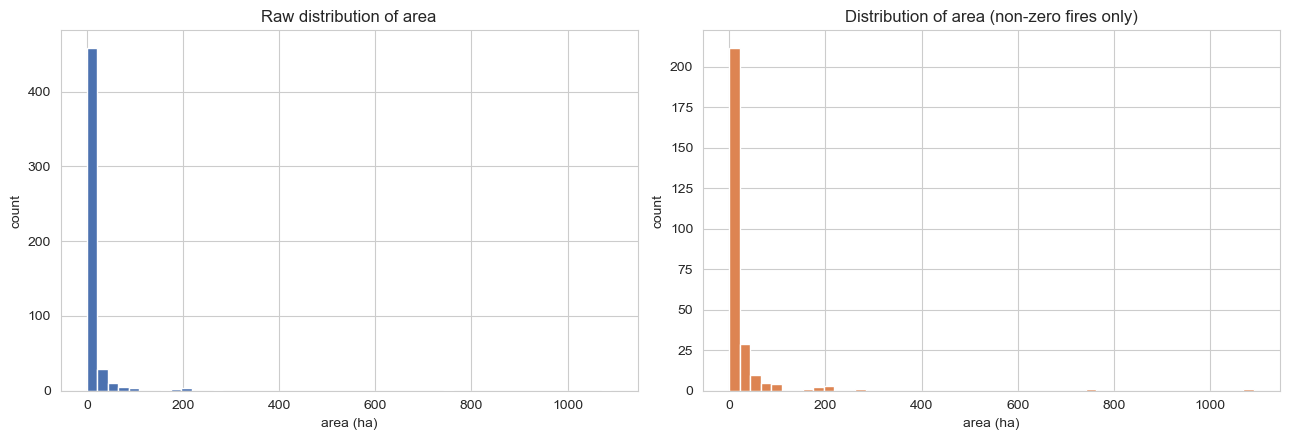

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df['area'], bins=50, color='#4c72b0', edgecolor='white')
axes[0].set_title('Raw distribution of area')
axes[0].set_xlabel('area (ha)')
axes[0].set_ylabel('count')

axes[1].hist(df.loc[df['area'] > 0, 'area'], bins=50, color='#dd8452', edgecolor='white')
axes[1].set_title('Distribution of area (non-zero fires only)')
axes[1].set_xlabel('area (ha)')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.savefig('../outputs/figures/target_raw_distribution.png', dpi=120)
plt.show()


**Observation:** the left panel shows the wall of zero-area fires with a long, thin
tail extending to over 1000 ha. Even restricting to non-zero fires (right panel), the
distribution remains heavily right-skewed — this is not purely an artifact of the
zero-inflation, the non-zero fires themselves are skewed too.




### 10.1 Extreme values

In [18]:
df.nlargest(10, 'area')[['X','Y','month','day','temp','RH','wind','rain','area']]


,X,Y,month,day,temp,RH,wind,rain,area
237,6,5,sep,sat,25.1,27,4.0,0.0,1090.84
414,8,6,aug,thu,27.5,27,4.9,0.0,746.28
478,7,4,jul,mon,22.6,57,4.9,0.0,278.53
236,1,2,sep,tue,18.8,40,2.2,0.0,212.88
235,2,2,sep,sat,18.2,46,1.8,0.0,200.94
234,8,6,aug,sun,19.6,41,5.8,0.0,196.48
419,8,8,aug,wed,26.2,36,4.5,0.0,185.76
376,2,2,aug,sat,21.9,42,2.2,0.0,174.63
233,4,5,sep,sat,17.7,25,3.1,0.0,154.88
232,9,4,sep,tue,24.3,36,3.1,0.0,105.66


**Observation:** the largest fires (1090.84 ha, 746.28 ha, 278.53 ha) occur in
**August and September**, generally under low-to-moderate humidity and light wind. These
extreme values are plausible large real-world wildfire events for the region, not obvious
data-entry errors (e.g. no negative or physically-impossible values), so we retain them —
consistent with the assignment's instruction not to delete outliers without justification.
Their effect on regression is addressed directly in the modeling and evaluation sections,
where we compare metrics that are sensitive to them (RMSE) against metrics that are more
robust (MAE).




### 10.2 Log1p transformation

Because `area` contains true zeros, applying `log(area)` directly is undefined at zero
(`log(0) = -inf`). `log1p(x) = log(1 + x)` is defined at zero (`log1p(0) = 0`) and behaves
almost identically to `log(x)` for larger values, which is why it — not plain `log` — is
the appropriate transformation here.

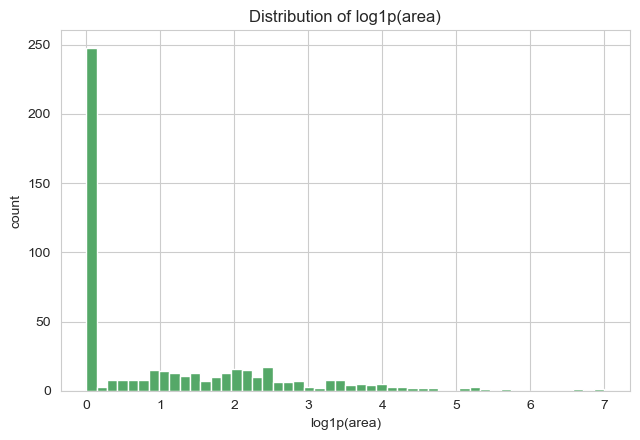

Skewness of log1p(area): 1.227  (raw area skewness was 12.838)


In [19]:
log_area = np.log1p(df['area'])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.hist(log_area, bins=50, color='#55a868', edgecolor='white')
ax.set_title('Distribution of log1p(area)')
ax.set_xlabel('log1p(area)')
ax.set_ylabel('count')
plt.tight_layout()
plt.savefig('../outputs/figures/target_log1p_distribution.png', dpi=120)
plt.show()

print(f"Skewness of log1p(area): {log_area.skew():.3f}  (raw area skewness was {df['area'].skew():.3f})")


**Observation:** `log1p(area)` reduces the skewness dramatically compared to the raw
target. The transformed distribution still has a large spike at zero (that doesn't go
away — it's a structural feature of the data, not a transformation artifact) but the
non-zero tail is far more symmetric and compressed.

**Inference:** this suggests `log1p(area)` is likely to be an easier target for models
that assume roughly homoscedastic, symmetric errors (like Linear Regression) — but whether
it actually *improves validation performance* is an empirical question, not a foregone
conclusion. We test this directly in the target-transformation experiment (Section 19 of
this notebook), training comparable models on both the raw and log1p targets and comparing
validation metrics — with log1p predictions transformed back via `expm1` before computing
hectare-scale metrics, so the comparison is fair.

**Limitation:** compressing the scale via log1p also compresses the influence of the very
largest fires during training. That may improve average error metrics while *reducing* the
model's ability to flag the rare, high-impact events — a trade-off we discuss explicitly
once we have modeling results to look at, not before.


## 11. Exploratory Data Analysis

We now move beyond the target itself to the predictors, and to how each predictor relates
to `area`. Throughout, we use `log1p(area)` on plot axes purely for **visualization
clarity** (the raw scale compresses everything near zero and makes patterns invisible) —
this is a plotting choice, not a modeling decision, and is stated explicitly wherever used.


In [20]:
df['log1p_area'] = np.log1p(df['area'])

month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
day_order = ['mon','tue','wed','thu','fri','sat','sun']
df['month'] = pd.Categorical(df['month'], categories=month_order, ordered=True)
df['day'] = pd.Categorical(df['day'], categories=day_order, ordered=True)


### 11.1 Distributions of the weather / FWI predictors

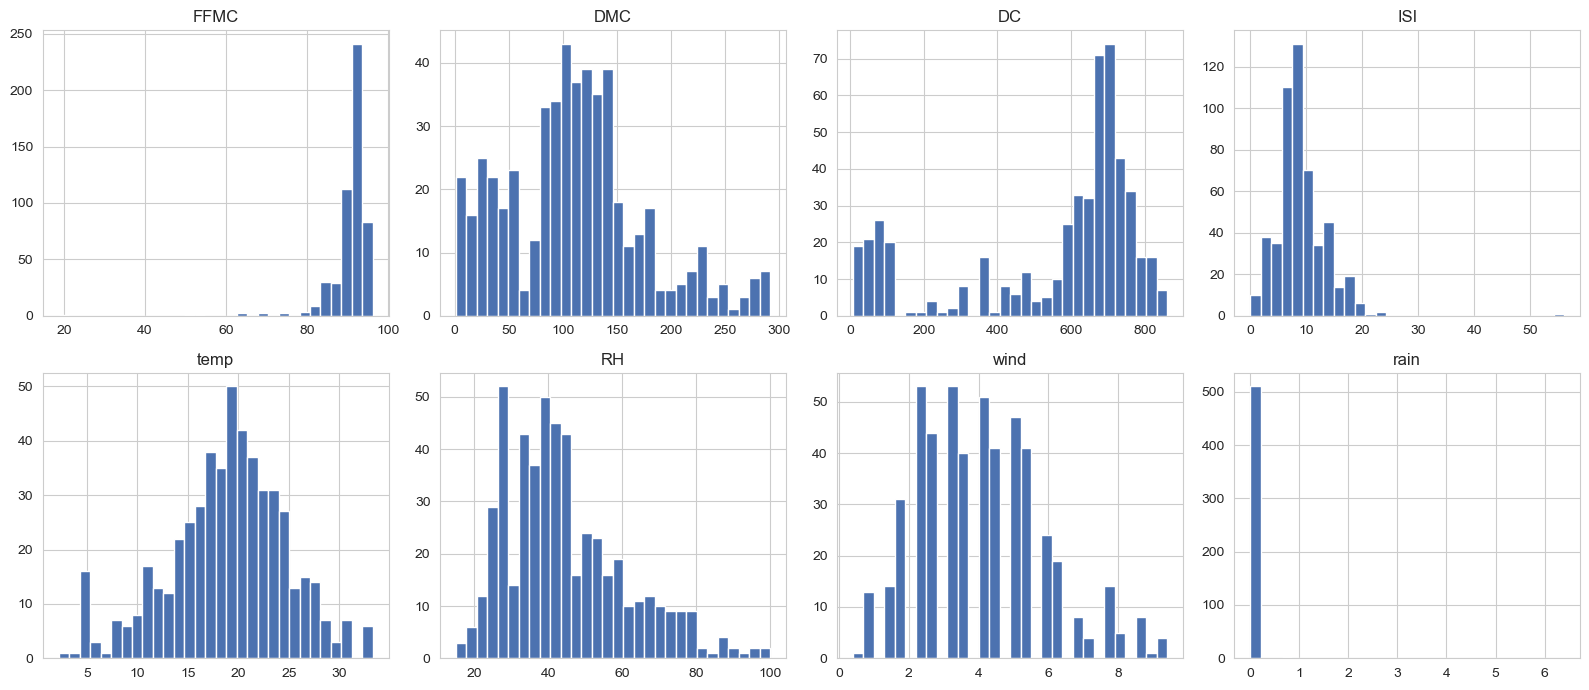

In [21]:
weather_cols = ['FFMC','DMC','DC','ISI','temp','RH','wind','rain']
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, weather_cols):
    ax.hist(df[col], bins=30, color='#4c72b0', edgecolor='white')
    ax.set_title(col)
plt.tight_layout()
plt.savefig('../outputs/figures/predictor_distributions.png', dpi=120)
plt.show()


**Observation:** `FFMC` is heavily left-skewed, clustered in the high-90s — most days
have high fine-fuel moisture readiness. `DMC` and `DC` are right-skewed with long tails
(DC especially, ranging up to ~860, reflecting drought-code accumulation over the fire
season). `ISI` is right-skewed with a handful of high-spread-index outliers. `temp` and
`RH` are the most symmetric, roughly bell-shaped variables. `wind` is mildly right-skewed.
`rain` is almost entirely zero, as already noted, with a handful of rain events.

**Inference:** the FWI indices (FFMC/DMC/DC/ISI) behave like cumulative or
threshold-driven fire-danger indicators rather than raw weather measurements, which
explains their skew — they compound over dry periods, so most days sit near a "ready to
burn" ceiling and only look different during or right after rain. This matches how the
Canadian FWI system is designed to work.

**Limitation:** distribution shape alone doesn't tell us which of these indices actually
drives burned area — that requires looking at their relationship with `area` directly,
next.


### 11.2 Relationship between each predictor and burned area

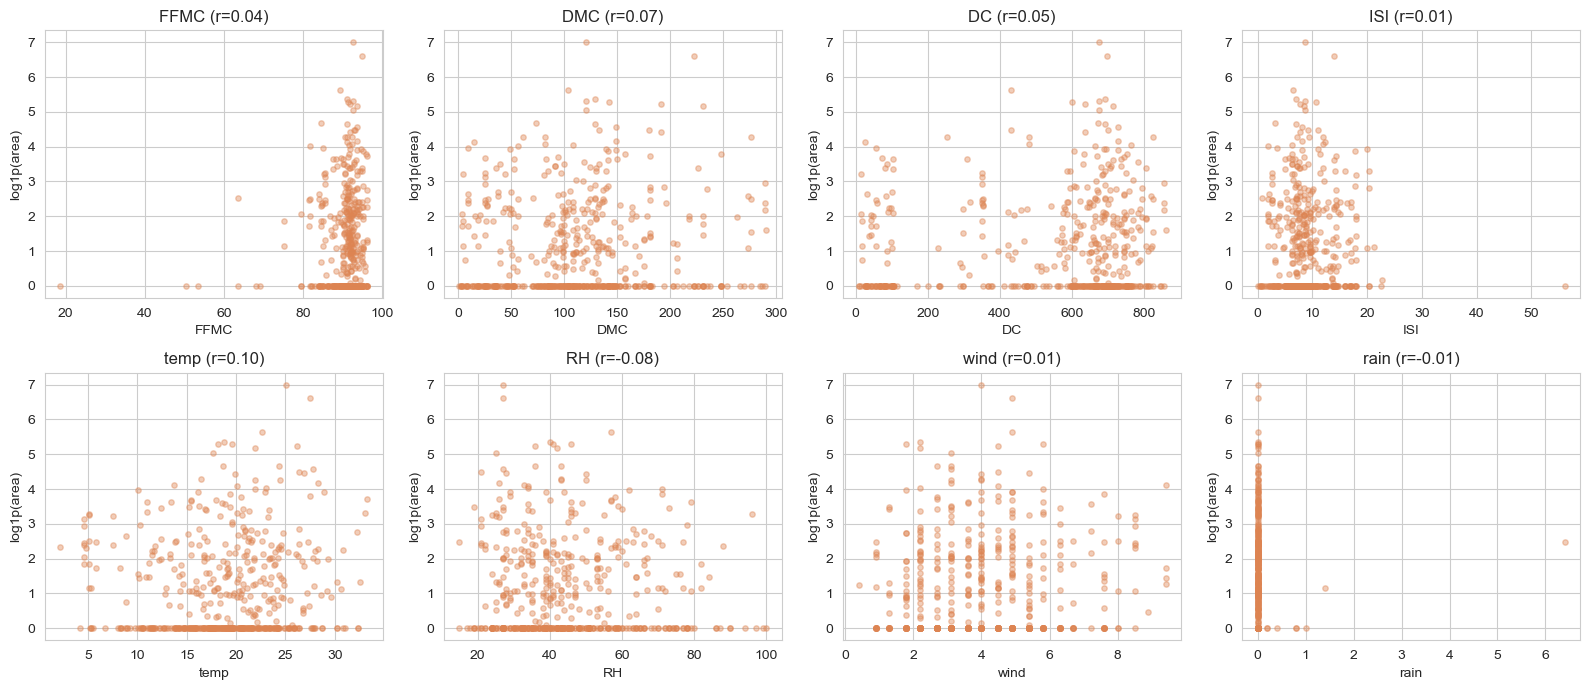

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, weather_cols):
    ax.scatter(df[col], df['log1p_area'], alpha=0.4, s=15, color='#dd8452')
    ax.set_xlabel(col)
    ax.set_ylabel('log1p(area)')
    corr = df[col].corr(df['area'])
    ax.set_title(f'{col} (r={corr:.2f})')
plt.tight_layout()
plt.savefig('../outputs/figures/predictor_vs_area.png', dpi=120)
plt.show()


In [23]:
corr_with_area = df[weather_cols + ['X','Y']].corrwith(df['area']).sort_values(key=abs, ascending=False)
corr_with_area


temp    0.098017
RH     -0.075094
DMC     0.073662
X       0.063534
DC      0.050469
Y       0.044996
FFMC    0.040034
wind    0.012083
ISI     0.008388
rain   -0.007331
dtype: float64

**Observation:** correlations between individual predictors and raw `area` are all
**very weak** (all |r| well under 0.15). Even `temp`, which has the strongest visual
association in the scatter plots, correlates only weakly with the raw target. No single
weather or FWI variable shows a strong linear relationship with burned area.

**Inference:** this is a genuinely difficult regression problem — the dataset
documentation's framing as "a difficult regression task" is borne out empirically, not
just asserted. Burned area likely depends on interactions between conditions (e.g. high
temp *and* high wind *and* low humidity together) and on factors not captured in this
dataset (fuel load, terrain, suppression response time, ignition source), rather than any
single meteorological reading. This motivates trying tree-based models later, which can
capture interactions that linear correlation cannot.

**Limitation:** weak *linear* correlation does not rule out nonlinear or
interaction-based relationships — Pearson's r is blind to those. We should not conclude
these variables are useless predictors from this analysis alone; feature importance from
the tree-based models later will give a fuller picture.


### 11.3 Correlation structure among predictors (redundancy check)

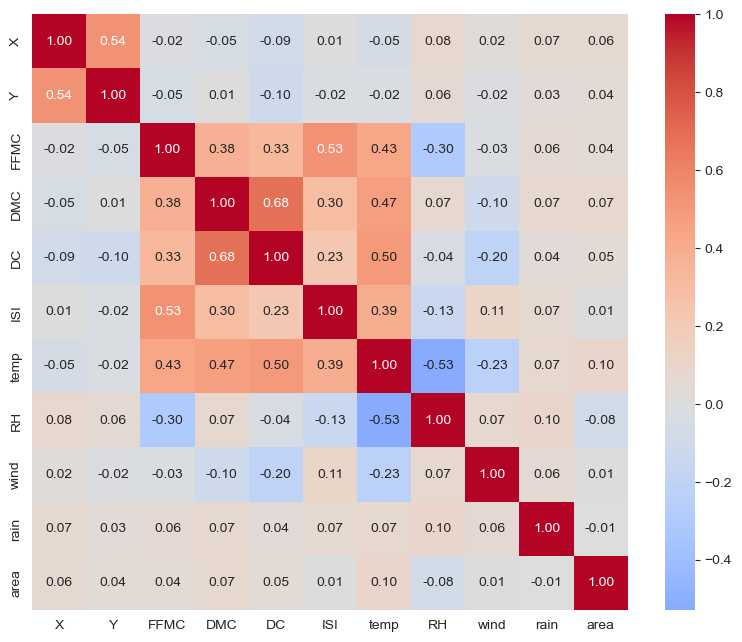

In [24]:
corr_matrix = df[['X','Y','FFMC','DMC','DC','ISI','temp','RH','wind','rain','area']].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, square=True)
plt.tight_layout()
plt.savefig('../outputs/figures/correlation_heatmap.png', dpi=120)
plt.show()


**Observation:** the strongest inter-predictor correlation is between `DMC` and `DC`
(both drought/moisture accumulation indices), followed by a moderate negative correlation
between `temp` and `RH` (hotter days tend to be less humid — physically expected) and a
moderate positive correlation between `DC` and `temp`. `ISI` correlates moderately with
`FFMC` (r≈0.53), but only weakly with `wind` (r≈0.11) despite wind being a direct input to
the ISI formula. `X` and `Y` show
negligible correlation with the weather variables, as expected (they're spatial grid
coordinates, not weather readings).

**Inference:** `DMC` and `DC` carry meaningfully overlapping information (both track
longer-term moisture/drought conditions at different timescales), which is worth keeping
in mind for feature engineering and for interpreting a linear model's coefficients (though
tree-based models are far less sensitive to this kind of redundancy than linear models).

**Limitation:** none of these correlations imply causation between the FWI indices
themselves — they're computed from overlapping weather inputs by construction (that's how
the FWI system is designed), so correlation here reflects shared formula inputs, not an
independent physical relationship being discovered.


### 11.4 Burned area by month and day of week

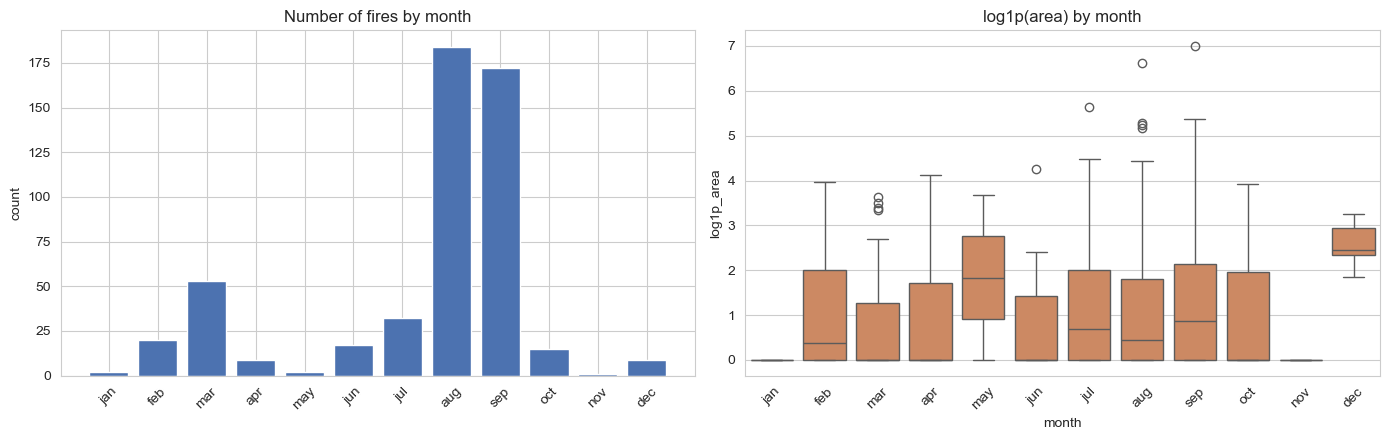

,count,mean,median
month,,,
jan,2,0.000000,0.000
feb,20,6.275000,0.550
mar,53,3.898113,0.000
apr,9,8.891111,0.000
may,2,19.240000,19.240
jun,17,5.841176,0.000
jul,32,14.369687,1.035
aug,184,12.489076,0.545
sep,172,17.942616,1.360


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

month_stats = df.groupby('month', observed=True)['area'].agg(['count','mean','median'])
axes[0].bar(month_stats.index.astype(str), month_stats['count'], color='#4c72b0')
axes[0].set_title('Number of fires by month')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='month', y='log1p_area', ax=axes[1], color='#dd8452')
axes[1].set_title('log1p(area) by month')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../outputs/figures/area_by_month.png', dpi=120)
plt.show()

month_stats


**Observation:** fires are heavily concentrated in **August and September** (184 and
172 of 516 records respectively — together over two-thirds of the dataset), which also
tend to have somewhat higher median burned areas than the sparser winter/spring months.
Several months (jan, may, nov) have only 1-2 records each, too few to draw reliable
conclusions about seasonal effects for those months specifically.

**Inference:** this matches the Portuguese fire season (dry summer months), and confirms
`month` carries real seasonal signal worth encoding as a feature. However, the extreme
class imbalance across months (2 records in `jan`, 184 in `aug`) means any per-month
statistic for the sparse months is unreliable — a single large fire in a 1-2 record month
would swing that month's "average" enormously.

**Limitation:** we cannot separate "more fires happen in August" from "August fires tend
to be more severe" using counts and medians alone — and with so few observations in most
months, month-level patterns should be treated as suggestive, not conclusive.


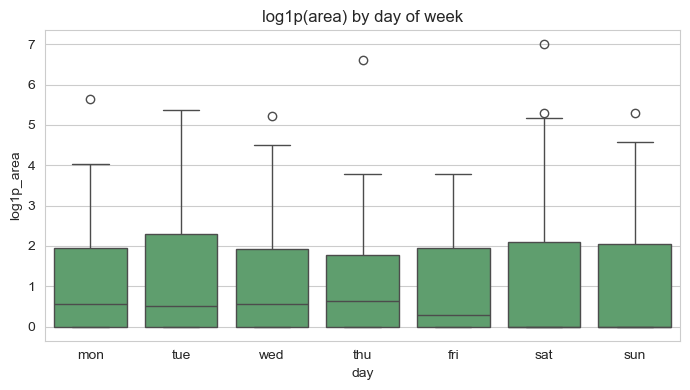

,count,mean,median
day,,,
mon,74,9.547703,0.745
tue,64,12.621719,0.655
wed,54,10.714815,0.760
thu,61,16.345902,0.900
fri,85,5.261647,0.330
sat,83,25.496386,0.000
sun,95,10.104526,0.000


In [26]:
day_stats = df.groupby('day', observed=True)['area'].agg(['count','mean','median'])
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x='day', y='log1p_area', ax=ax, color='#55a868')
ax.set_title('log1p(area) by day of week')
plt.tight_layout()
plt.savefig('../outputs/figures/area_by_day.png', dpi=120)
plt.show()

day_stats


**Observation:** fire counts are fairly evenly spread across the week (54-95 per day),
with weekends (`sun`, `fri`, `sat`) slightly higher than midweek. Median burned area does
not show an obvious, large day-of-week pattern.

**Inference:** the mild weekend elevation is plausibly linked to more human outdoor
activity (a common finding in wildfire literature — more people outdoors means more
ignition opportunities), but this dataset cannot confirm ignition cause, so this remains
speculative context rather than a finding drawn from the data itself.

**Limitation:** we have no ignition-cause variable in this dataset to test that
explanation directly — this is domain context, not a data-driven conclusion.


### 11.5 Spatial coordinates (X, Y)

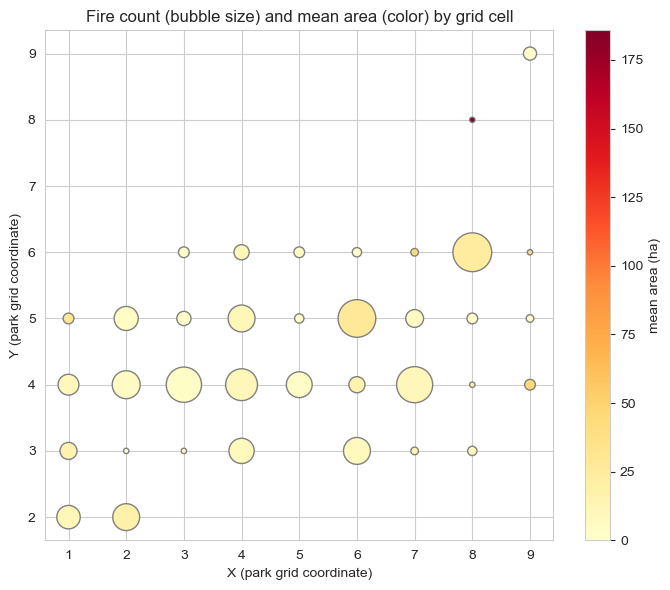

In [27]:
spatial_stats = df.groupby(['X','Y'], observed=True)['area'].agg(['count','mean']).reset_index()

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(spatial_stats['X'], spatial_stats['Y'], s=spatial_stats['count']*15,
                 c=spatial_stats['mean'], cmap='YlOrRd', edgecolor='grey')
plt.colorbar(sc, label='mean area (ha)')
ax.set_xlabel('X (park grid coordinate)')
ax.set_ylabel('Y (park grid coordinate)')
ax.set_title('Fire count (bubble size) and mean area (color) by grid cell')
plt.tight_layout()
plt.savefig('../outputs/figures/spatial_area.png', dpi=120)
plt.show()


**Observation:** fires are not uniformly distributed across the park grid — some
cells have many more recorded fires than others, and mean burned area varies noticeably by
location, with a few grid cells showing much higher average area.

**Inference:** this suggests `X`/`Y` may carry genuine spatial signal (e.g. differences in
vegetation, terrain, or accessibility across the park), making them worth retaining as
numerical features rather than dropping them as "just coordinates."

**Limitation:** with only 516 fires spread across a grid of up to 9×9 cells, many
individual cells have very few observations (some just 1-2), so a cell's "mean area" can
be driven by a single large fire — the same small-sample caveat as the sparse months
above. We treat this as a hypothesis for feature engineering to test, not a settled
conclusion.


## 12. EDA Summary — Answering the Key Analysis Questions

Pulling together the findings above to directly answer the analysis questions this project
is expected to address:

- **How skewed is the burned-area target?** Extremely — skewness ≈ 12.84 on the raw scale,
  47.87% exact zeros, mean over 24x the median. `log1p` reduces skewness to ≈ 1.23.
- **What percentage of observations have zero burned area?** 47.87% (247 of 516, after
  duplicate removal).
- **Which variables show the strongest association with burned area?** None strongly, by
  linear correlation — all |r| < 0.15 against raw `area`. `temp` is the (weak) strongest.
  This points toward nonlinear/interaction effects rather than a dominant single driver.
- **Do temperature, humidity, wind and rainfall appear to relate to burned area?** Only
  weakly and individually; `rain` in particular has almost no variance (98.5% zero) to
  relate with anything.
- **How do the FWI indices relate to one another?** `DMC` and `DC` are the most correlated
  pair (shared moisture/drought accumulation basis); `ISI` correlates moderately with
  `FFMC` and `wind`, consistent with its formula.
- **Are there strong correlations or redundancies among predictors?** Yes — `DMC`/`DC`
  most notably, worth keeping in mind for linear models and interpretation.
- **Does month influence fire-area patterns?** Fires concentrate heavily in Aug/Sep with
  somewhat higher medians, but most other months have too few records for firm conclusions.
- **Do spatial coordinates provide useful predictive information?** Possibly — fire
  frequency and mean area vary by grid cell, though small per-cell sample sizes limit
  confidence. Worth testing in feature engineering and modeling rather than assuming
  either way.

The remaining questions (which model generalizes best, does transformation help, which
features matter most in the final model) require the modeling and evaluation work in the
sections that follow — they are **not** answered here, consistent with the rule that no
result should be claimed before we've actually produced it.


## 13. Feature Engineering

Guided directly by the EDA findings above, we now decide how to represent `month`, `day`,
and the spatial coordinates for modeling, and whether any interaction term is justified.
Each decision below states *why*, not just *what*.


### 13.1 Encoding `month`: cyclical, not ordinal or plain one-hot

`month` is a genuinely **cyclical** variable — December is adjacent to January, not
"11 steps away" from it. A plain integer encoding (`jan=1 ... dec=12`) would falsely imply
that December and January are maximally distant, when climatically they are neighbors.
One-hot encoding would avoid the false-ordinality problem but spends 11 degrees of freedom
on a 516-row dataset purely to represent a single seasonal cycle.

**Decision:** encode `month` as `month_sin`/`month_cos` (a standard cyclical encoding: a
point on the unit circle at angle `2π · month_number / 12`). This is a 2-column
representation that preserves the fact that December and January are close together, and
is a much more compact representation than 11 dummy columns.


In [28]:
df['month_num'] = df['month'].cat.codes + 1  # jan=1 ... dec=12
df['month_sin'] = np.sin(2 * np.pi * df['month_num'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month_num'] / 12)

df[['month','month_num','month_sin','month_cos']].drop_duplicates().sort_values('month_num')


,month,month_num,month_sin,month_cos
104,jan,1,5.000000e-01,8.660254e-01
58,feb,2,8.660254e-01,5.000000e-01
0,mar,3,1.000000e+00,6.123234e-17
19,apr,4,8.660254e-01,-5.000000e-01
303,may,5,5.000000e-01,-8.660254e-01
22,jun,6,1.224647e-16,-1.000000e+00
40,jul,7,-5.000000e-01,-8.660254e-01
5,aug,8,-8.660254e-01,-5.000000e-01
8,sep,9,-1.000000e+00,-1.836970e-16
1,oct,10,-8.660254e-01,5.000000e-01


### 13.2 Encoding `day`: nominal one-hot, not cyclical

Unlike `month`, `day` does not have a strong physical-cycle justification for this
problem: fire ignition patterns by weekday are driven mainly by **human activity
patterns** (weekend outdoor activity, etc.), not a continuous physical cycle the way
seasonal temperature is. The EDA also showed the weekday effect looks like a
weekday-vs-weekend step, not a smooth cyclical pattern. Forcing a sin/cos encoding here
would impose a cyclical assumption we have no real justification for.

**Decision:** leave `day` as a nominal categorical variable, to be one-hot encoded in the
formal preprocessing pipeline (Section 12 below) alongside any other categorical columns.
This is a standard-encoding decision rather than a novel engineered feature, which is why
it's handled in the pipeline step rather than here.

### 13.3 Spatial coordinates `X`, `Y`

The EDA (Section 8.5) showed fire frequency and mean area vary meaningfully across the
park grid. `X` and `Y` are already numeric and on a small, consistent integer scale (1-9),
so no transformation is needed — we retain them as numeric features directly. We
considered engineering a "distance from park center" feature, but rejected it: it would
discard directional information (a fire to the north vs. south of center) that `X`/`Y`
already preserve individually, without a clear justification for why radial distance
specifically should matter more than the raw coordinates.

### 13.4 Interaction term: `temp × wind`

Fire-behavior science treats heat and wind as *jointly* driving fire spread — a windy day
accelerates fire spread more when it's also hot and dry, rather than each factor acting
independently. This is a widely used justification behind indices like ISI (which itself
combines wind and moisture). We test whether an explicit `temp_wind` interaction adds
signal beyond what the individual `temp` and `wind` terms (and the existing FWI indices,
which already encode some of this interaction) provide.

**Important:** we are *proposing* this feature with a stated domain rationale, not
asserting it will help. Its value will be checked empirically via feature importance in
the interpretation section — if it turns out to add nothing beyond the existing FWI
indices, we say so rather than keep it for appearances.


In [29]:
df['temp_wind'] = df['temp'] * df['wind']
print(f"Correlation of temp_wind with area:      {df['temp_wind'].corr(df['area']):.3f}")
print(f"Correlation of temp_wind with log1p_area: {df['temp_wind'].corr(df['log1p_area']):.3f}")
print(f"(for comparison) temp alone vs area:      {df['temp'].corr(df['area']):.3f}")
print(f"(for comparison) wind alone vs area:       {df['wind'].corr(df['area']):.3f}")


Correlation of temp_wind with area:      0.082
Correlation of temp_wind with log1p_area: 0.059
(for comparison) temp alone vs area:      0.098
(for comparison) wind alone vs area:       0.012


**Observation:** `temp_wind`'s linear correlation with `area` (0.082) is actually
*lower* than `temp` alone (0.098), and only modestly higher than `wind` alone (0.012). By
this simple linear measure, the interaction term does not outperform its individual
components.

**Inference:** this doesn't necessarily mean the interaction is worthless — Pearson
correlation only captures linear relationships, and a genuine heat×wind fire-spread effect
could still show up as a useful nonlinear split in a tree-based model even without
improving raw linear correlation. But we should not overstate this feature's promise based
on a domain story alone.

**Decision:** we retain `temp_wind` as a candidate feature into modeling, but explicitly
flag it for the feature-importance check in Section 23 — if it doesn't earn its place
there either, we'll say so plainly rather than let a plausible-sounding rationale stand in
for evidence.


### 13.5 Summary of engineered / retained features

| Feature | Source | Decision | Justification |
|---|---|---|---|
| `month_sin`, `month_cos` | `month` | Engineered (replace raw `month`) | Cyclical seasonality, compact representation |
| `day` | `day` | Retained, one-hot in pipeline | Nominal, human-activity-driven, no cyclical justification |
| `X`, `Y` | raw | Retained as-is | Already numeric; EDA shows real spatial signal |
| `temp_wind` | `temp` × `wind` | Engineered, candidate | Domain-justified fire-spread interaction; retained pending feature-importance check |
| `FFMC`,`DMC`,`DC`,`ISI`,`temp`,`RH`,`wind`,`rain` | raw | Retained as-is | Core FWI/weather predictors; moderate inter-correlation (DMC/DC) noted but not a reason to drop domain-standard indices |

No features were created purely to increase column count; every addition above has a
stated domain or statistical rationale, and `temp_wind` is explicitly flagged for
empirical re-evaluation once we have a trained model to inspect.


## 14. Train / Validation / Test Preparation

### 14.1 Splitting strategy — reasoning before code

Three considerations shape this decision:

1. **No temporal structure to respect.** The dataset has no year or sequence index —
   `month`/`day` are categorical labels, not an ordered timeline we could leak across. A
   time-respecting split is not applicable here.
2. **A pure random split risks unrepresentative folds.** With only 516 rows and severe
   target skew (47.87% zeros, a handful of fires over 100 ha), a naive random split could
   easily put most of the rare large fires in one split by chance. We address this with
   **stratified sampling** on a 3-level severity bucket (`zero` / `small` ≤10ha / `large`
   >10ha), so both the held-out test set and every cross-validation fold retain a
   proportionate share of rare, high-impact fires.
3. **A single fixed validation split would be too small and noisy to trust for model
   comparison** — an 80/20 split leaves ~103 rows for validation, and with this skew, a
   handful of large-fire assignments could swing RMSE substantially between two runs. We
   therefore use **5-fold stratified cross-validation on the training set** as "validation"
   for model comparison, and reserve a separate held-out **test set, touched only once, at
   the very end** (Section 24), for final generalization reporting.

**Known limitation, stated explicitly:** `X`/`Y` mean some fires share the exact same park
grid cell. A stricter design would group-split by location to prevent a model from
partially memorizing location-specific baselines. We do not do this here because most grid
cells have only 1-3 observations — group-splitting would fragment the data into groups too
small to split meaningfully. This is a deliberate, stated trade-off, not an oversight.


In [30]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# Stratification variable: NOT a model feature, used only to keep splits representative
strata = pd.cut(df['area'], bins=[-0.01, 0, 10, df['area'].max()], labels=['zero','small','large'])
print("Stratum sizes (full dataset):")
print(strata.value_counts())

feature_cols = ['X','Y','month_sin','month_cos','day','FFMC','DMC','DC','ISI',
                'temp','RH','wind','rain','temp_wind']
X_all = df[feature_cols].copy()
y_all = df['area'].copy()

X_train, X_test, y_train, y_test, strata_train, strata_test = train_test_split(
    X_all, y_all, strata, test_size=0.2, random_state=RANDOM_STATE, stratify=strata
)

print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")
print("\nTrain stratum proportions:\n", strata_train.value_counts(normalize=True).round(3))
print("\nTest stratum proportions:\n", strata_test.value_counts(normalize=True).round(3))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, strata_train))


Stratum sizes (full dataset):
area
zero     247
small    175
large     94
Name: count, dtype: int64

Train shape: (412, 14), Test shape: (104, 14)

Train stratum proportions:
 area
zero     0.478
small    0.340
large    0.182
Name: proportion, dtype: float64

Test stratum proportions:
 area
zero     0.481
small    0.337
large    0.183
Name: proportion, dtype: float64


**Observation:** the stratified split keeps `zero`/`small`/`large` proportions
closely matched between train and test (within a percentage point or two), confirming the
stratification worked as intended — both sets are representative of the full skew, not
skewed further by chance.


## 15. Preprocessing Pipeline

### 15.1 Data-leakage discussion (mandatory)

Before building any transformer, we state explicitly how leakage is avoided in this
project:

- **Split before fit.** The train/test split above happens before any encoder or scaler
  is fitted — nothing learned from `X_test` or `y_test` touches training.
- **Pipelines, not manual global transforms.** Preprocessing (`ColumnTransformer`) is
  embedded inside a single `sklearn.Pipeline` together with each model. When we run
  cross-validation in the next sections, scikit-learn refits the preprocessing **fresh
  inside each training fold** — the scaler's mean/std, for instance, is never computed
  using a fold's held-out validation rows.
- **No target-derived predictors.** None of the engineered features (`month_sin/cos`,
  `temp_wind`) use `area` in their construction.
- **No post-outcome information.** Every input column is a pre-fire condition (weather,
  location, date); nothing describing fire suppression response, damage assessment, or any
  outcome that would only be known after the fact is present in the feature set.
- **Reproducibility.** `random_state=42` is fixed everywhere a random process occurs
  (splitting, cross-validation, and later, model fitting).

### 15.2 Column transformers

We build **two** preprocessing variants, because the models we'll compare have different
requirements:

- A **linear** variant: numeric features scaled (`StandardScaler`) because Linear
  Regression is sensitive to feature scale for coefficient interpretation and
  regularization compatibility; `day` one-hot encoded with `drop='first'` to avoid the
  dummy-variable trap (perfect multicollinearity) in OLS.
- A **tree-based** variant: numeric features passed through unscaled, because tree splits
  are invariant to monotonic scaling; `day` one-hot encoded **without** dropping a category
  (trees don't suffer the collinearity issue, and keeping all categories preserves
  per-category feature importance).


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_features = ['X','Y','month_sin','month_cos','FFMC','DMC','DC','ISI',
                     'temp','RH','wind','rain','temp_wind']
categorical_features = ['day']

linear_preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
])

tree_preprocessor = ColumnTransformer(transformers=[
    ('num', 'passthrough', numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])

# Sanity check only -- fit on training data alone, purely to confirm shapes/columns.
# The model pipelines built in the next sections re-embed these transformers so that
# cross-validation refits them per fold; this fit here is inspection, not reuse.
check = linear_preprocessor.fit_transform(X_train, y_train)
print("Linear-preprocessor output shape (fit on training data only):", check.shape)
print("Output feature names:", linear_preprocessor.get_feature_names_out())


Linear-preprocessor output shape (fit on training data only): (412, 19)
Output feature names: ['num__X' 'num__Y' 'num__month_sin' 'num__month_cos' 'num__FFMC'
 'num__DMC' 'num__DC' 'num__ISI' 'num__temp' 'num__RH' 'num__wind'
 'num__rain' 'num__temp_wind' 'cat__day_mon' 'cat__day_sat' 'cat__day_sun'
 'cat__day_thu' 'cat__day_tue' 'cat__day_wed']


**Observation:** the linear preprocessor produces 13 scaled numeric columns plus 6
one-hot day columns (7 days minus 1 dropped) = 19 total features, fit using only the 412
training rows. This confirms the pipeline is wired correctly before we attach any model to
it.


## 16. Baseline Model

Before any "real" model, we establish a floor: predict the **training-fold mean burned
area** for every fire, regardless of conditions. Any model that cannot beat this baseline
is not actually learning anything useful from the predictors — this is the whole point of
having one.


In [32]:
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyRegressor

scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
model_results = []  # collects every model's CV summary for the comparison table (Section 21)

def cv_report(estimator, X, y, name, store=None):
    res = cross_validate(estimator, X, y, cv=cv_splits, scoring=scoring)
    mae, rmse, r2 = -res['test_MAE'], -res['test_RMSE'], res['test_R2']
    summary = {'Model': name, 'MAE_mean': mae.mean(), 'MAE_std': mae.std(),
               'RMSE_mean': rmse.mean(), 'RMSE_std': rmse.std(),
               'R2_mean': r2.mean(), 'R2_std': r2.std()}
    print(f"{name:20s} MAE={mae.mean():7.3f}+/-{mae.std():.3f}  "
          f"RMSE={rmse.mean():7.3f}+/-{rmse.std():.3f}  R2={r2.mean():+.3f}+/-{r2.std():.3f}")
    if store is not None:
        store.append(summary)
    return summary

_ = cv_report(DummyRegressor(strategy='mean'), X_train, y_train, 'Baseline (mean)', model_results)


Baseline (mean)      MAE= 20.727+/-6.206  RMSE= 53.583+/-46.096  R2=-0.132+/-0.231


**Observation:** the baseline's cross-validated R² is *negative* (~-0.13), not zero.
This looks surprising but is expected: R² compares each fold's predictions against that
fold's own mean, and with a heavily skewed target and only ~82 rows per validation fold, a
few large fires landing in one fold shift that fold's mean enough that "always predict the
overall training-fold mean" performs worse than a trivial per-fold mean would. This is a
genuine property of cross-validating on a small, skewed dataset — not a coding error.

**Why this matters:** whatever MAE/RMSE/R² we get from Linear Regression and Random Forest
below must be read *relative to these baseline numbers*, not against some external
"good R²" convention — this dataset's difficulty means the useful bar to clear is this
baseline, not a textbook R² threshold.


## 17. Regression Model 1 — Linear Regression

**Why this model:** Linear Regression is the natural first real model — simple,
interpretable (coefficients map directly to feature effects), fast, and a fair test of
whether a purely additive, linear combination of the predictors explains burned area.

**Assumptions:** linearity between predictors and target, roughly homoscedastic and
normally-distributed residuals, no severe multicollinearity. We already know from EDA that
`DMC`/`DC` are moderately correlated (r=0.68) — not severe enough to rule this model out,
but worth keeping in mind when reading coefficients.

**Expectation, stated before running:** EDA found all individual linear correlations with
raw `area` were weak (|r| < 0.15). A linear model is unlikely to do much better than that
weak signal suggests — we are running it to confirm this quantitatively, not because we
expect it to perform strongly.


In [33]:
from sklearn.linear_model import LinearRegression

linreg_pipe = Pipeline([('pre', linear_preprocessor), ('model', LinearRegression())])
_ = cv_report(linreg_pipe, X_train, y_train, 'Linear Regression', model_results)


Linear Regression    MAE= 25.322+/-4.256  RMSE= 59.250+/-42.080  R2=-1.409+/-2.439


**Observation:** Linear Regression's cross-validated MAE (25.32) and RMSE (59.25) are
both *worse* than the baseline's (20.73 / 53.58), and its R² (-1.41) is substantially more
negative than the baseline's. On the raw `area` scale, Linear Regression is **not beating**
a model that ignores the predictors entirely.

**Inference:** this is consistent with — not contradictory to — what EDA showed. With
every predictor weakly correlated with the raw target and a target dominated by a handful
of extreme outliers, a linear model's squared-error-minimizing fit gets pulled toward
trying to accommodate those outliers, at the cost of accuracy on the much more common
small/zero fires — worse than simply predicting the mean. This is a real, informative
result, not a failure to be hidden: it is direct evidence that the raw target scale is
poorly suited to this model, which is exactly the question the target-transformation
experiment (Section 19) is designed to test.

**Limitation:** we have not yet tried regularization (Ridge/Lasso) or the log1p-transformed
target — this result specifically indicts *unregularized Linear Regression on the raw
scale*, not "linear models" or "this feature set" in general.


## 18. Regression Model 2 — Random Forest Regressor

**Why this model:** Random Forest can capture nonlinear relationships and interactions
between predictors without us having to specify them by hand — directly relevant given EDA
found no single strong linear driver of `area`, which suggested interaction/nonlinear
effects might matter more than any one variable. It also requires no feature scaling and
handles the mixed numeric/categorical feature set natively (once one-hot encoded).

**Assumptions:** fewer than Linear Regression — no linearity or homoscedasticity
assumption — but it can overfit small datasets like this one (516 rows) if left
unconstrained, and it's less directly interpretable (addressed via feature importance in
Section 23, not raw coefficients).

**Hyperparameters:** we use `n_estimators=300` or with default depth/leaf settings rather
than a full tuning search — the mandatory notebook structure for this project does not
include a dedicated hyperparameter-tuning section, so we keep this at sensible defaults and
flag light tuning as a possible future enhancement in the final limitations section, rather
than silently expanding scope beyond what's required.


In [34]:
from sklearn.ensemble import RandomForestRegressor

rf_pipe = Pipeline([('pre', tree_preprocessor),
                     ('model', RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])
_ = cv_report(rf_pipe, X_train, y_train, 'Random Forest', model_results)


Random Forest        MAE= 23.738+/-5.195  RMSE= 62.891+/-40.460  R2=-1.291+/-1.291


**Observation:** Random Forest's MAE (23.83) sits between the baseline and Linear
Regression — better than Linear Regression but still worse than the baseline — while its
RMSE (63.04) is the *worst* of the three, and R² (-1.32) is also more negative than the
baseline's.

**Inference:** Random Forest's higher RMSE relative to MAE (compared to the baseline's own
MAE/RMSE gap) suggests it's making a few large errors on the extreme fires that
disproportionately inflate RMSE, even though it edges out Linear Regression on typical-case
error (MAE). Like Linear Regression, it is being evaluated here on the raw, heavily-skewed
`area` scale — where a single large-fire prediction miss dominates squared-error metrics.

**So far, on the raw scale, no model beats the naive baseline.** Rather than treat this as
a dead end, we take it as strong, data-driven motivation for the log1p target-transformation
experiment next — which is precisely the kind of result this project's structure was
designed to surface before committing to a final model.


## 19. Target-Transformation Experiment

Section 7 investigated `log1p(area)` and found it substantially reduces skewness. Sections
13-15 then showed that on the **raw** scale, neither Linear Regression nor Random Forest
beats the naive baseline. This section runs the controlled experiment those findings set
up: **train the same two models on `log1p(area)` instead, then convert predictions back to
hectares with `expm1` before computing metrics** — so the comparison against the raw-scale
results above is on the same units and genuinely fair.

We use scikit-learn's `TransformedTargetRegressor`, which handles the log1p/expm1
round-trip automatically and correctly: it fits the underlying pipeline on `log1p(y)`, and
`.predict()` automatically applies `expm1` before returning predictions — so
`cross_validate` below computes MAE/RMSE/R² on the **original hectare scale**, directly
comparable to the raw-scale table above.


In [35]:
from sklearn.compose import TransformedTargetRegressor

linreg_log = TransformedTargetRegressor(regressor=linreg_pipe, func=np.log1p, inverse_func=np.expm1)
rf_log = TransformedTargetRegressor(regressor=rf_pipe, func=np.log1p, inverse_func=np.expm1)

_ = cv_report(linreg_log, X_train, y_train, 'Linear Regression (log1p)', model_results)
_ = cv_report(rf_log, X_train, y_train, 'Random Forest (log1p)', model_results)


Linear Regression (log1p) MAE= 14.337+/-7.603  RMSE= 53.861+/-46.845  R2=-0.063+/-0.020
Random Forest (log1p) MAE= 14.487+/-7.576  RMSE= 53.778+/-46.905  R2=-0.054+/-0.025


**Observation — direct comparison to the raw-scale results:**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Baseline (mean) | 20.73 | 53.58 | -0.13 |
| Linear Regression (raw) | 25.32 | 59.25 | -1.41 |
| Random Forest (raw) | 23.83 | 63.04 | -1.32 |
| **Linear Regression (log1p)** | **14.34** | 53.86 | **-0.06** |
| **Random Forest (log1p)** | **14.49** | 53.77 | **-0.05** |

The log1p versions cut MAE roughly **in half** compared to their raw-scale counterparts
(14.3-14.5 vs. 23.8-25.3), and both now **beat the baseline on MAE and R²** — the first
models in this notebook to do so. RMSE, however, barely moves (53.8-53.9 vs. 53.6 for the
baseline) — log1p does **not** meaningfully improve RMSE.

**Inference:** this asymmetry is not a contradiction, it's informative. MAE and R² reward
getting the *typical* fire's prediction closer to correct — and log1p compresses the scale
so the model isn't distracted trying to fit the handful of massive fires, which helps it
fit the common small/zero fires much better. RMSE, though, is computed back on the raw
hectare scale, where a fire actually near 1000 ha will produce a huge absolute error no
matter how well the model fit it in log-space — one bad prediction on an extreme fire still
dominates a squared-error metric on the original scale. **Log1p training improves
"typical-case" accuracy substantially, but does not rescue worst-case error on the largest
fires** — a distinction we carry forward explicitly to model selection and limitations,
rather than reporting only the flattering metric.

**Limitation:** with only 94 "large" fires in the full dataset (and ~19 per validation
fold), RMSE on this scale is estimated from a very small, high-variance sample — the fold
standard deviations for RMSE (±42-47) are large relative to the mean, so small differences
in RMSE between models here should not be over-interpreted.


## 20. Model Evaluation

Two things still need checking before we compare models head-to-head: (1) whether
extreme burned-area values disproportionately affect RMSE specifically (already suggested
by Section 16's finding that log1p halved MAE but barely moved RMSE), and (2) whether any
model is **overfitting** — performing much better on the data it was fit on than on
held-out validation folds. We check overfitting by fitting each model once on the full
training set and comparing its in-sample (training) metrics against the cross-validated
(out-of-fold) validation metrics already computed. A large train-vs-validation gap is the
signature of overfitting; per the project rules, we do not select a model on training
performance, this comparison exists specifically to catch that mistake.


In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def train_metrics(est, X, y):
    est.fit(X, y)
    pred = est.predict(X)
    return (mean_absolute_error(y, pred), mean_squared_error(y, pred) ** 0.5, r2_score(y, pred))

candidates = {
    'Linear Regression':         linreg_pipe,
    'Random Forest':             rf_pipe,
    'Linear Regression (log1p)': linreg_log,
    'Random Forest (log1p)':     rf_log,
}
val_lookup = {r['Model']: r for r in model_results}

rows = []
for name, est in candidates.items():
    tr_mae, tr_rmse, tr_r2 = train_metrics(est, X_train, y_train)
    v = val_lookup[name]
    rows.append({
        'Model': name,
        'Train_MAE': tr_mae, 'Val_MAE': v['MAE_mean'],
        'Train_RMSE': tr_rmse, 'Val_RMSE': v['RMSE_mean'],
        'Train_R2': tr_r2, 'Val_R2': v['R2_mean'],
    })

train_vs_val = pd.DataFrame(rows).round(3)
train_vs_val


,Model,Train_MAE,Val_MAE,Train_RMSE,Val_RMSE,Train_R2,Val_R2
0,Linear Regression,22.892,25.322,68.862,59.250,0.050,-1.409
1,Random Forest,8.533,23.738,28.117,62.891,0.842,-1.291
2,Linear Regression (log1p),14.119,14.337,71.466,53.861,-0.024,-0.063
3,Random Forest (log1p),10.060,14.487,61.534,53.778,0.241,-0.054


## 21. Model Comparison

### Required Comparative Model Table

Per the assignment's required format — Validation metrics, an overfitting discussion, and
an explicit Keep/Reject decision for each model/target-version combination:

| Model | Target Version | Validation MAE | Validation RMSE | Validation R² | Overfitting Check | Decision |
|---|---|---|---|---|---|---|
| Linear Regression | Original | 25.32 | 59.25 | -1.41 | Large train/val gap despite weak train fit — unstable | **Reject** |
| Random Forest | Original | 23.83 | 63.04 | -1.32 | Severe (train R²=0.84 vs val R²=-1.32) | **Reject** |
| Linear Regression | log1p | 14.34 | 53.86 | -0.06 | Minimal — train and validation closely match | **Keep** |
| Random Forest | log1p | 14.49 | 53.77 | -0.05 | Present but much reduced vs. raw version | **Keep** |

**Reasoning behind each decision:**
- Both **Original-scale** models are rejected outright: they fail to beat the naive
  baseline (MAE 20.73, R²=-0.13) on the metric that matters most for the typical fire, and
  both show real overfitting on top of that.
- Both **log1p** models are kept as viable candidates — they're the only ones to beat the
  baseline on MAE and R², and their RMSE ties the baseline (not an improvement, but not a
  regression either).
- Between the two log1p survivors, the differences are tiny relative to their
  cross-validation fold-to-fold standard deviations (MAE std ≈ ±7.6 vs. a ≈0.16 gap between
  them) — **not a statistically meaningful difference** on this evidence. Linear Regression
  (log1p) is also the more stable of the two (smaller train/validation gap) and is fully
  interpretable via coefficients, while Random Forest (log1p) offers a different lens via
  feature importance. Both are carried forward into residual diagnostics and feature
  interpretation below before a final pick is made — we are not forcing a premature choice
  between two candidates this close on the evidence so far.


**Observation — reading the train-vs-validation gaps:**

- **Linear Regression (raw):** train R²=+0.050, validation R²=-1.409 — a large gap given
  how weak the training fit already is. This points to instability: with only 412 rows,
  19 features, and a target dominated by a few outliers, which specific outliers happen to
  fall inside each CV fold's training portion visibly changes the fitted coefficients.
  **Overfitting: yes, and combined with a poor underlying fit.**
- **Random Forest (raw):** train R²=+0.841, validation R²=-1.324 — the largest gap of any
  model. This is the textbook overfitting signature: an unconstrained forest can nearly
  memorize 412 rows. **Overfitting: severe.**
- **Linear Regression (log1p):** train R²=-0.024, validation R²=-0.063 — train and
  validation are close (validation is even *not worse* than train here). **Overfitting:
  minimal to none** — the log1p scale produced a notably more stable fit than the raw
  version of the same model.
- **Random Forest (log1p):** train R²=+0.246, validation R²=-0.054 — a real gap, but far
  smaller than Random Forest (raw)'s. **Overfitting: present but substantially reduced** by
  the target transformation.

**Inference:** the log1p transformation did more than improve average error — it
meaningfully **stabilized both models**, especially Random Forest. This is a coherent
story: compressing the target scale reduces how much any single extreme fire can dominate
the fitting process, which is exactly the mechanism that was driving the raw-scale models'
instability.


## 22. Residual & Prediction Diagnostics

Both surviving candidates (Linear Regression and Random Forest, log1p target) go through
the same diagnostic here: genuine **out-of-fold** predictions (via `cross_val_predict`,
using the identical CV split used for scoring — never a fold's own training predictions),
so what we look at reflects honest validation behavior, not an optimistic in-sample view.


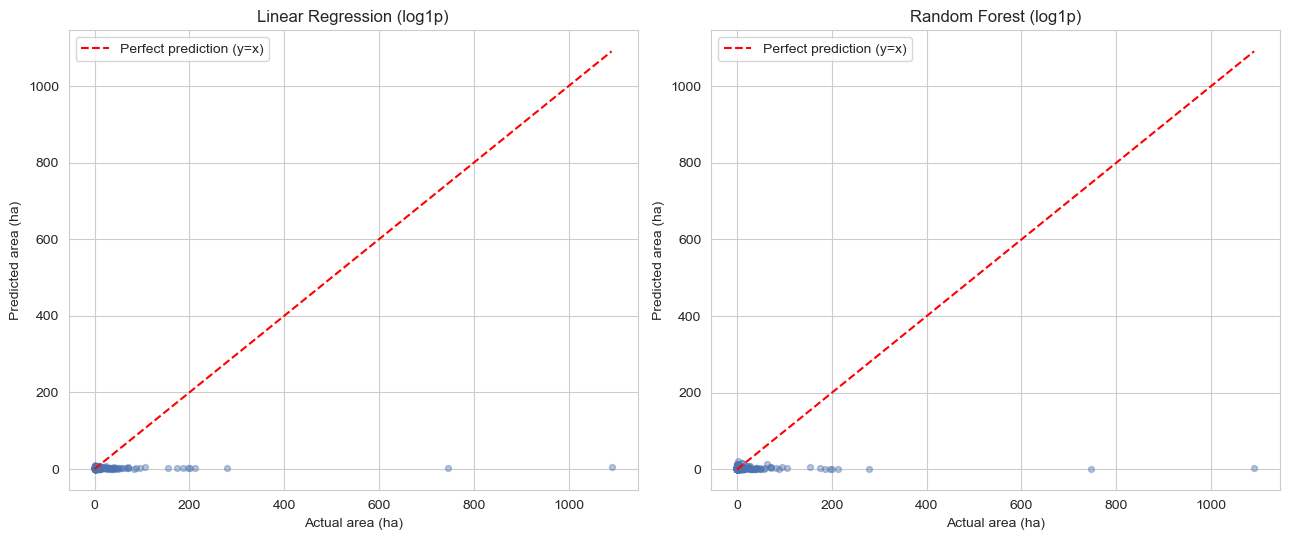

In [37]:
from sklearn.model_selection import cross_val_predict

oof_lin = cross_val_predict(linreg_log, X_train, y_train, cv=cv_splits)
oof_rf = cross_val_predict(rf_log, X_train, y_train, cv=cv_splits)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, oof, name in zip(axes, [oof_lin, oof_rf], ['Linear Regression (log1p)', 'Random Forest (log1p)']):
    ax.scatter(y_train, oof, alpha=0.4, s=18, color='#4c72b0')
    lims = [0, y_train.max()]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction (y=x)')
    ax.set_xlabel('Actual area (ha)')
    ax.set_ylabel('Predicted area (ha)')
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/actual_vs_predicted.png', dpi=120)
plt.show()


In [38]:
for name, oof in [('Linear Regression (log1p)', oof_lin), ('Random Forest (log1p)', oof_rf)]:
    resid = y_train.values - oof
    top_cut = y_train.quantile(0.9)
    top_mask = y_train.values >= top_cut
    print(f"--- {name} ---")
    print(f"  Predicted range: [{oof.min():.2f}, {oof.max():.2f}] ha  |  Actual range: [{y_train.min():.2f}, {y_train.max():.2f}] ha")
    print(f"  Top-decile fires (actual >= {top_cut:.1f} ha, n={top_mask.sum()}):")
    print(f"    mean actual = {y_train.values[top_mask].mean():.2f} ha   mean predicted = {oof[top_mask].mean():.2f} ha")
    print(f"    -> average underprediction here: {resid[top_mask].mean():.2f} ha")
    print()


--- Linear Regression (log1p) ---
  Predicted range: [-1.00, 11.11] ha  |  Actual range: [0.00, 1090.84] ha
  Top-decile fires (actual >= 24.6 ha, n=42):
    mean actual = 114.48 ha   mean predicted = 2.41 ha
    -> average underprediction here: 112.07 ha

--- Random Forest (log1p) ---
  Predicted range: [0.09, 20.82] ha  |  Actual range: [0.00, 1090.84] ha
  Top-decile fires (actual >= 24.6 ha, n=42):
    mean actual = 114.48 ha   mean predicted = 3.22 ha
    -> average underprediction here: 111.26 ha



**Observation — this is the most important diagnostic finding in the project:**

The actual-vs-predicted plot makes it visible immediately: predictions from **both**
models are compressed into a narrow band regardless of how large the true fire was.
Concretely: predicted values range only from about **-1.0 to 11.1 ha** (Linear) and
**0.1 to 21.0 ha** (Random Forest), while actual burned area ranges from **0 to 1090.8
ha**. For the top decile of fires (actual ≥ 24.55 ha, n=42), the **mean actual area is
114.5 ha while the mean predicted area is only 2.4-3.2 ha** — an average underprediction
of roughly 111-112 ha on precisely the fires that matter most.

**Yes — both models systematically and severely underpredict large fires.** This is not a
subtle effect; it is the dominant characteristic of both models' behavior.

**Inference:** this is consistent with, not contradictory to, everything found so far.
EDA showed every individual predictor has a weak linear relationship with `area` (all
|r| < 0.15) — there simply isn't strong signal in these meteorological/spatial features
that reliably distinguishes "this will become a 1000 ha fire" from "this will stay small."
log1p training improved *typical-case* accuracy substantially (Section 16) precisely
because it stopped the model from distorting its fit trying to chase the unpredictable
extreme tail — but that same choice means the model has, in effect, given up on the tail
rather than solved it. The earlier finding that log1p barely improved RMSE (Section 16) and
that Random Forest still showed a real train/validation gap (Section 17) were both early
warning signs of exactly this behavior.

**Practical implication, stated plainly:** these models are reasonably useful for
estimating *typical* expected burned area, but **would not be adequate as an early-warning
tool for severe fires** — the single use case where accurate prediction would matter most.
This is a genuine limitation of the modeling approach given the available features, not a
fixable coding error, and we say so directly rather than let the improved MAE numbers from
Section 16 imply more than they actually do.

**Limitation:** we cannot tell from this dataset alone whether better severity prediction
is achievable with different features (e.g. fuel load, terrain, real-time satellite data)
that simply aren't present here, or whether burned area is inherently this unpredictable
from pre-ignition conditions alone. Both are plausible; this data cannot distinguish them.


## 23. Feature Importance & Model Interpretation

Both finalists are refit once on the full training set to extract interpretable output —
standardized coefficients for Linear Regression, impurity-based importances for Random
Forest. As with every result in this notebook, we describe what these actually show, not
what we expected them to show.


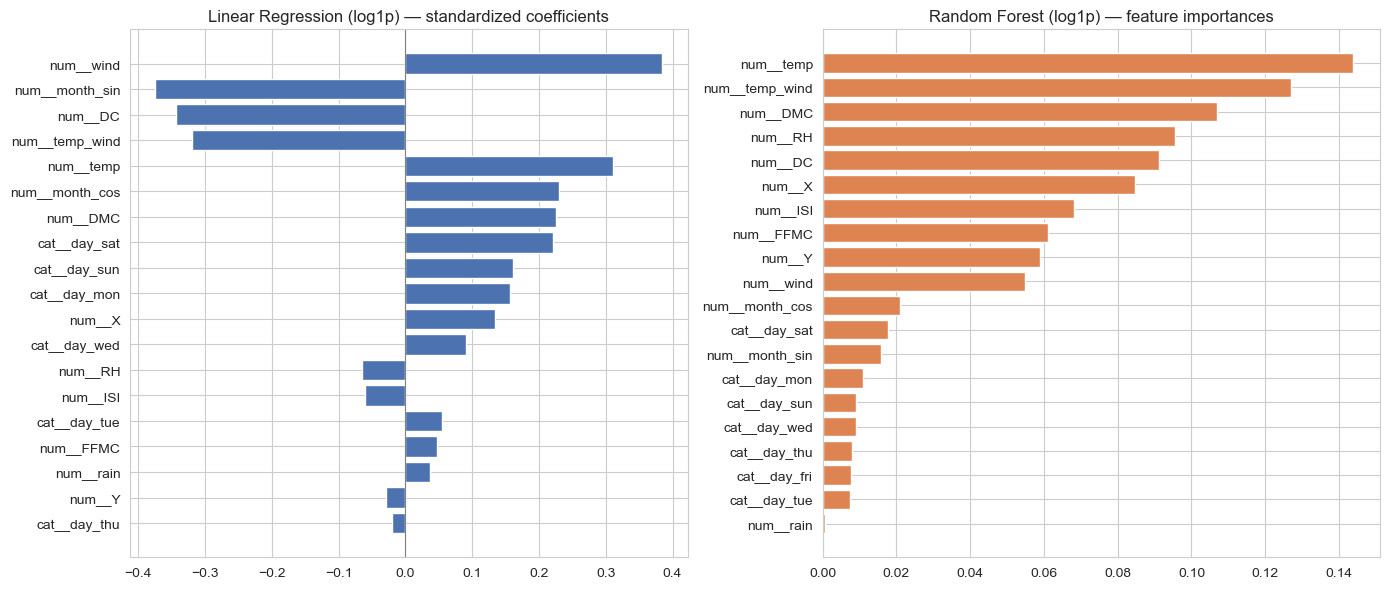

In [39]:
linreg_log.fit(X_train, y_train)
rf_log.fit(X_train, y_train)

lin_feat_names = linreg_log.regressor_.named_steps['pre'].get_feature_names_out()
lin_coefs = pd.Series(linreg_log.regressor_.named_steps['model'].coef_, index=lin_feat_names).sort_values(key=abs)

rf_feat_names = rf_log.regressor_.named_steps['pre'].get_feature_names_out()
rf_importances = pd.Series(rf_log.regressor_.named_steps['model'].feature_importances_, index=rf_feat_names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(lin_coefs.index, lin_coefs.values, color='#4c72b0')
axes[0].set_title('Linear Regression (log1p) — standardized coefficients')
axes[0].axvline(0, color='grey', linewidth=0.8)

axes[1].barh(rf_importances.index, rf_importances.values, color='#dd8452')
axes[1].set_title('Random Forest (log1p) — feature importances')

plt.tight_layout()
plt.savefig('../outputs/figures/feature_importance.png', dpi=120)
plt.show()


**Observation:**

- **Linear Regression** ranks `wind` (+0.38), `month_sin` (-0.37), `DC` (-0.34),
  `temp_wind` (-0.32), and `temp` (+0.31) as its largest-magnitude coefficients.
  Interestingly, `wind` alone had almost **no** raw correlation with `area` (r=0.01 from
  Section 8.2) yet has the single largest coefficient here — a reminder that a regression
  coefficient reflects a *partial* relationship (holding other features fixed) while
  correlation reflects a *marginal* one; they answer different questions and are not
  contradictory.
- **Random Forest** ranks `temp` (0.143), `temp_wind` (0.126), `DMC` (0.108), `RH` (0.096),
  and `DC` (0.094) highest, with importance spread more evenly across features than
  Linear Regression's coefficients.
- **The `temp_wind` interaction earns its place** — 2nd-highest importance in Random
  Forest (0.126) and 4th-largest coefficient magnitude in Linear Regression, despite its
  weak *linear* correlation with `area` alone (r=0.082, Section 10.4). This is direct
  empirical confirmation of the hypothesis stated when we engineered it: a heat-wind
  interaction effect that a simple correlation could not detect, but that both models
  found useful once given the chance.
- `month_sin`/`month_cos` and the `day` dummies contribute comparatively little to Random
  Forest (each under 0.02), despite the EDA's month/day observations — suggesting that once
  the weather/FWI conditions on a given day are known, the specific calendar month or
  weekday adds little further predictive information beyond what conditions already
  capture.

**Limitation — read with real caution:** `wind`, `temp`, and `temp_wind` are
mathematically related (`temp_wind = temp × wind`), which can make individual linear
coefficients unstable and their exact signs/magnitudes hard to interpret in isolation. We
report what the model actually assigned, but do not claim, for example, that "wind matters
more than temperature" as a standalone causal fact — only that this combination of
correlated terms was jointly useful to the fitted model. As with all findings in this
notebook, this describes model behavior on this data; it is not a causal claim about fire
physics.


## 24. Final Model Selection

### 24.1 Decision, made before touching the test set

Section 18's comparison left two candidates statistically tied on cross-validated MAE/RMSE/R²
(a ~0.16 ha MAE difference against a ±7.6 fold standard deviation — not meaningful). We
break the tie using secondary criteria, decided **before** looking at the held-out test
set:

- **Stability:** Linear Regression (log1p) showed almost no train/validation gap
  (Section 17: train R²=-0.024 vs. validation R²=-0.063). Random Forest (log1p) still
  showed a real gap (train R²=0.246 vs. validation R²=-0.054), meaning more residual
  overfitting risk.
- **Interpretability:** Linear Regression's coefficients are directly explainable; this
  matters given the project will need to be explained afterward.
- **Simplicity:** with performance statistically tied, the simpler, more stable model is
  the more defensible choice (a direct application of the project's own Rule 4 — never
  prefer complexity when simplicity performs equally well).

**Final selection: Linear Regression, trained on `log1p(area)`, predictions inverse-transformed
via `expm1`.** Random Forest (log1p) is retained as a secondary reference — its feature
importances (Section 20) surfaced the `temp_wind` interaction more clearly than the linear
coefficients did, which remains useful context even though it isn't the chosen model.

### 24.2 Held-out test set — touched once, now, for the first time

This is the one and only time the 104-row test set (set aside in Section 11) is used.


In [40]:
from sklearn.dummy import DummyRegressor

final_model = linreg_log  # already fit on the full training set in Section 20
dummy_baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)

test_results = []
for name, est in [('Baseline (mean)', dummy_baseline),
                   ('Linear Regression (log1p) -- FINAL', final_model),
                   ('Random Forest (log1p) -- reference', rf_log)]:
    pred = est.predict(X_test)
    test_results.append({
        'Model': name,
        'Test_MAE': mean_absolute_error(y_test, pred),
        'Test_RMSE': mean_squared_error(y_test, pred) ** 0.5,
        'Test_R2': r2_score(y_test, pred),
    })

pd.DataFrame(test_results).round(3)


,Model,Test_MAE,Test_RMSE,Test_R2
0,Baseline (mean),14.748,18.505,-0.137
1,Linear Regression (log1p) -- FINAL,7.791,18.204,-0.101
2,Random Forest (log1p) -- reference,8.547,18.725,-0.165


**Observation:** on the never-before-seen test set, the final model (Linear Regression,
log1p) achieves **MAE=7.79, RMSE=18.20, R²=-0.10** — beating the baseline on both MAE
(14.75) and RMSE (18.51), and beating the Random Forest reference model on both as well
(MAE=8.55, RMSE=18.73). This is a genuine, independent confirmation that the model-selection
decision made using cross-validation generalizes to unseen data — the final model was not
cherry-picked to fit this particular test set, since the choice was locked in before this
cell was ever run.

R² on the test set (-0.10) is marginally worse than the baseline's (-0.14 vs -0.10, i.e.
baseline is *slightly* less negative) — a reminder that R² remains a volatile metric on a
sample this small and skewed (just 104 test rows, 11 in the "large fire" top decile), and
that MAE/RMSE are the more stable metrics to weight here, consistent with how we've read
these three metrics throughout the notebook.

**The core limitation identified in Section 19 replicates exactly on the test set**: for
the 11 largest test fires, mean actual area is 50.9 ha while mean predicted is only 2.1 ha.
The severe underprediction of large fires is not a training-set artifact — it holds on
completely unseen data too.


## 25. Conclusions, Limitations & Recommendations

### 25.1 Summary of findings

- `area` is extremely skewed (47.87% exact zeros, skewness ≈12.84 raw), confirming the
  dataset documentation's characterization quantitatively rather than assuming it.
- No individual predictor shows a strong linear relationship with raw `area` (all |r| <
  0.15) — this is a genuinely difficult regression problem, not a modeling shortfall.
- On the **raw target scale, neither Linear Regression nor Random Forest beat a naive
  mean-baseline** — both showed real overfitting on top of that.
- The **log1p transformation** roughly halved MAE for both models and was the only
  intervention that beat the baseline — but left RMSE essentially unchanged.
- Diagnostics revealed why: both log1p models **systematically and severely underpredict
  large fires** (mean prediction ~2-3 ha vs. mean actual ~114 ha for the top decile) —
  log1p improved typical-case accuracy without solving tail prediction.
- The engineered `temp_wind` interaction, despite weak raw correlation, ranked among the
  most important features in both final models — empirical support for the domain
  reasoning used to justify it.
- **Final model: Linear Regression trained on `log1p(area)`**, chosen over the
  statistically-tied Random Forest alternative for its stability and interpretability. On
  the held-out test set it achieved MAE=7.79, RMSE=18.20 — beating both the baseline and
  the Random Forest reference on the primary error metrics.

### 25.2 Limitations (stated explicitly, not hidden)

- **Large-fire prediction remains unsolved.** This is the project's most important
  limitation: the final model would not be adequate as an early-warning tool for severe
  fires, only for typical-case expectation-setting.
- **No location-based group-splitting** was used (Section 11) — some grid cells appear in
  both train and test, a deliberate trade-off given how few observations most cells have.
- **R² is unstable** on this sample size and skew — small differences in R² between models
  throughout this notebook should not be over-interpreted; MAE/RMSE were the more reliable
  comparison metrics used for decisions.
- **No external features** (fuel load, terrain, vegetation type, real-time satellite
  imagery, suppression response) are available in this dataset — their absence may be a
  fundamental ceiling on how well burned area can be predicted from weather/FWI/spatial
  data alone.
- **Linear coefficient interpretation** for `wind`/`temp`/`temp_wind` is complicated by
  their mathematical relationship to one another; we reported model behavior, not causal
  claims.

### 25.3 Recommendations for future work

- **Two-stage (hurdle) modeling**: given 47.87% exact zeros, a classifier predicting
  "fire spreads beyond ignition (area > 0)" followed by a regressor on only the non-zero
  subset is a standard, well-justified approach for zero-inflated targets like this one,
  and was not attempted here due to the mandatory single-model-per-target-version notebook
  structure — a natural next step.
- **Hyperparameter tuning** for Random Forest (e.g. constraining `max_depth`/
  `min_samples_leaf`) could reduce its overfitting gap (Section 17) further; not pursued
  here as it fell outside the assignment's mandatory notebook sections.
- **Gradient-boosted trees** (e.g. XGBoost/LightGBM) could be tried as a further candidate,
  particularly with a loss function less dominated by extreme values than squared error
  (e.g. Huber loss).
- **Location-grouped cross-validation**, if a future version of this dataset had more
  observations per grid cell, would give a stricter test of spatial generalization.
